In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sqlalchemy import create_engine, text
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv(usecwd=True))
engine = create_engine(os.environ["DATABASE_URL"])
IMG_DIR = Path.cwd().parent / "images"
IMG_DIR.mkdir(exist_ok=True)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b4b2a9"
CAT_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10, "axes.axisbelow": True,
})

def q(sql):
    df = pd.read_sql(text(sql), engine)
    for c in df.columns:                      # Postgres numeric -> Python float
        if df[c].dtype == object:
            try:
                df[c] = pd.to_numeric(df[c])
            except (ValueError, TypeError):
                pass
    return df

In [2]:
metrics = q("select * from marts.mart_fund_metrics where is_active")
pairs   = q("select * from marts.mart_direct_vs_regular")
rolling = q("select * from marts.mart_rolling_returns")
dq      = q("select issue, count(*) as rows, count(distinct scheme_code) as schemes from marts.dq_nav_issues group by 1")

overview = pd.Series({
    "Active schemes": len(metrics),
    "Direct / Regular": f"{(metrics.plan_type=='Direct').sum()} / {(metrics.plan_type=='Regular').sum()}",
    "Categories": metrics.sub_category.nunique(),
    "Fund houses": metrics.fund_house.nunique(),
    "Direct-Regular pairs": len(pairs),
    "Data as of": metrics.as_of.max(),
})
display(overview.to_frame("value"))
display(dq)

,value
Active schemes,1147
Direct / Regular,572 / 575
Categories,15
Fund houses,48
Direct-Regular pairs,570
Data as of,2026-10-12


,issue,rows,schemes
0,big_move_kept,24,24
1,gap_over_10_days,8,4
2,spike_removed,2,2
3,stale_nav_5_days,19,7


Median yearly gap (Direct minus Regular, 3y CAGR): 1.27%
Direct beat Regular in 100% of 399 fund pairs


,pairs,median_gap_pct,direct_wins_pct
sub_category,,,
ELSS,17,1.17,100.00
Value Fund,20,1.20,100.00
Large & Mid Cap Fund,26,1.20,100.00
Large Cap Fund,30,1.21,100.00
Mid Cap Fund,28,1.21,100.00
Dividend Yield Fund,9,1.25,100.00
ELSS- Tax Saver Fund,20,1.25,100.00
Contra Fund,3,1.25,100.00
Sectoral/ Thematic,100,1.25,100.00


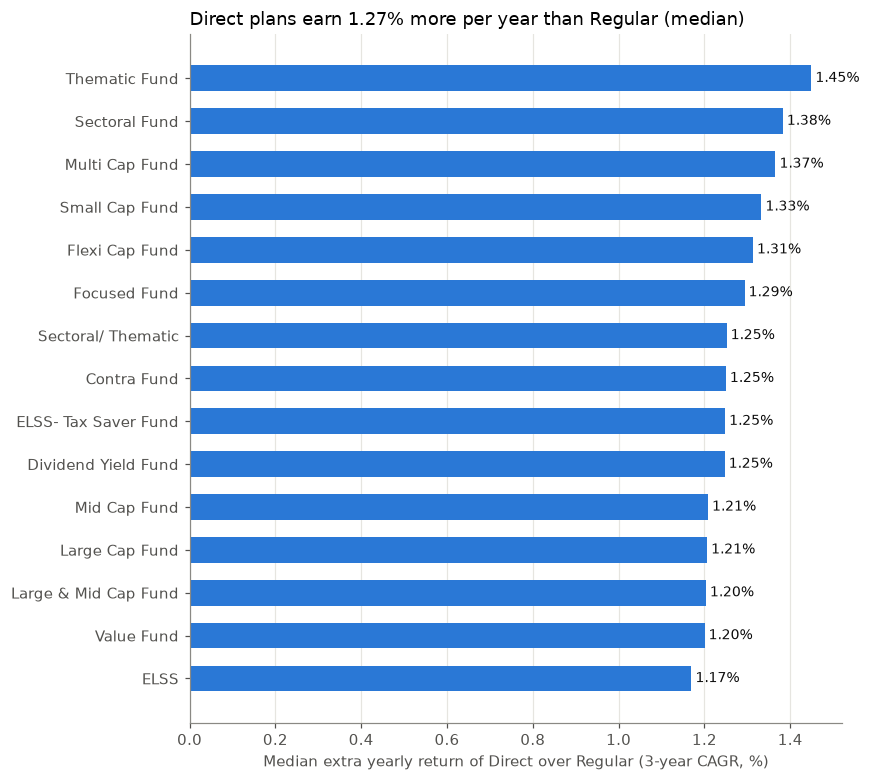

In [3]:
p3 = pairs.dropna(subset=["gap_3y"])
by_cat = (p3.groupby("sub_category")
            .agg(pairs=("gap_3y", "size"),
                 median_gap_pct=("gap_3y", lambda s: s.median() * 100),
                 direct_wins_pct=("gap_3y", lambda s: (s > 0).mean() * 100))
            .query("pairs >= 3")
            .sort_values("median_gap_pct"))
overall_gap = p3.gap_3y.median()
print(f"Median yearly gap (Direct minus Regular, 3y CAGR): {overall_gap*100:.2f}%")
print(f"Direct beat Regular in {(p3.gap_3y > 0).mean()*100:.0f}% of {len(p3)} fund pairs")
display(by_cat.round(2))

fig, ax = plt.subplots(figsize=(8, 0.4 * len(by_cat) + 1.2))
ax.barh(by_cat.index, by_cat.median_gap_pct, color=BLUE, height=0.6)
for y, v in enumerate(by_cat.median_gap_pct):
    ax.text(v, y, f" {v:.2f}%", va="center", color="#0b0b0b", fontsize=9)
ax.axvline(0, color="#8a8984", linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Median extra yearly return of Direct over Regular (3-year CAGR, %)")
ax.set_title(f"Direct plans earn {overall_gap*100:.2f}% more per year than Regular (median)", loc="left", fontsize=12)
plt.tight_layout(); plt.savefig(IMG_DIR / "direct_vs_regular_gap.png", bbox_inches="tight"); plt.show()

Assumed Direct return 11.35%  vs  Regular 10.09%
Values in ₹ lakh


Horizon,10 years,20 years
₹10L lump sum: Direct,29.31,85.90
₹10L lump sum: Regular,26.14,68.35
₹10k SIP: Direct,21.64,85.08
₹10k SIP: Regular,20.24,73.15
Lump sum lost to Regular,3.16,17.55
SIP lost to Regular,1.41,11.93


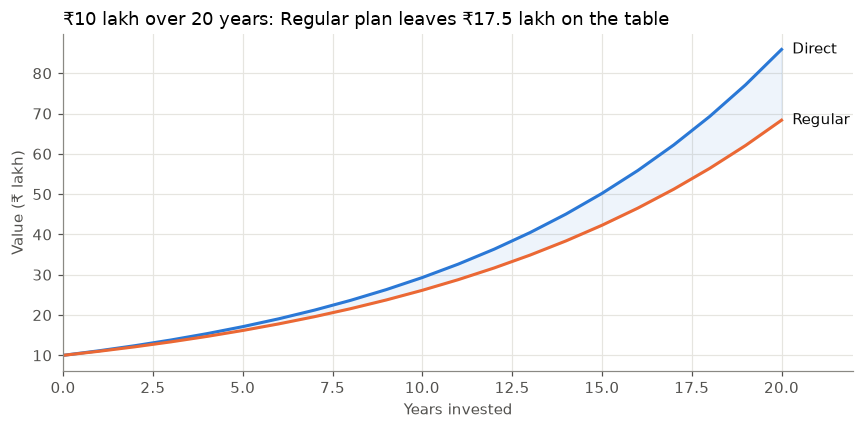

In [4]:
direct_rate = p3.direct_cagr_3y.median()
regular_rate = direct_rate - overall_gap
years = np.arange(0, 21)
lump, sip = 1_000_000, 10_000

def sip_value(rate, months):
    r = (1 + rate) ** (1 / 12) - 1
    return sip * ((1 + r) ** months - 1) / r * (1 + r)

growth = pd.DataFrame({
    "year": years,
    "direct": lump * (1 + direct_rate) ** years,
    "regular": lump * (1 + regular_rate) ** years,
})
impact = pd.DataFrame({
    "Horizon": ["10 years", "20 years"],
    "₹10L lump sum: Direct": [lump*(1+direct_rate)**10, lump*(1+direct_rate)**20],
    "₹10L lump sum: Regular": [lump*(1+regular_rate)**10, lump*(1+regular_rate)**20],
    "₹10k SIP: Direct": [sip_value(direct_rate, 120), sip_value(direct_rate, 240)],
    "₹10k SIP: Regular": [sip_value(regular_rate, 120), sip_value(regular_rate, 240)],
})
impact["Lump sum lost to Regular"] = impact["₹10L lump sum: Direct"] - impact["₹10L lump sum: Regular"]
impact["SIP lost to Regular"] = impact["₹10k SIP: Direct"] - impact["₹10k SIP: Regular"]
print(f"Assumed Direct return {direct_rate*100:.2f}%  vs  Regular {regular_rate*100:.2f}%")
print("Values in ₹ lakh")
display((impact.set_index("Horizon").T / 1e5).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(growth.year, growth.direct / 1e5, color=BLUE, linewidth=2)
ax.plot(growth.year, growth.regular / 1e5, color=ORANGE, linewidth=2)
ax.fill_between(growth.year, growth.regular / 1e5, growth.direct / 1e5, color=BLUE, alpha=0.08)
ax.text(20.3, growth.direct.iloc[-1] / 1e5, "Direct", color="#0b0b0b", va="center")
ax.text(20.3, growth.regular.iloc[-1] / 1e5, "Regular", color="#0b0b0b", va="center")
gap20 = (growth.direct.iloc[-1] - growth.regular.iloc[-1]) / 1e5
ax.set_title(f"₹10 lakh over 20 years: Regular plan leaves ₹{gap20:.1f} lakh on the table", loc="left", fontsize=12)
ax.set_xlabel("Years invested"); ax.set_ylabel("Value (₹ lakh)")
ax.set_xlim(0, 22)
plt.tight_layout(); plt.savefig(IMG_DIR / "cost_of_regular_20y.png", bbox_inches="tight"); plt.show()

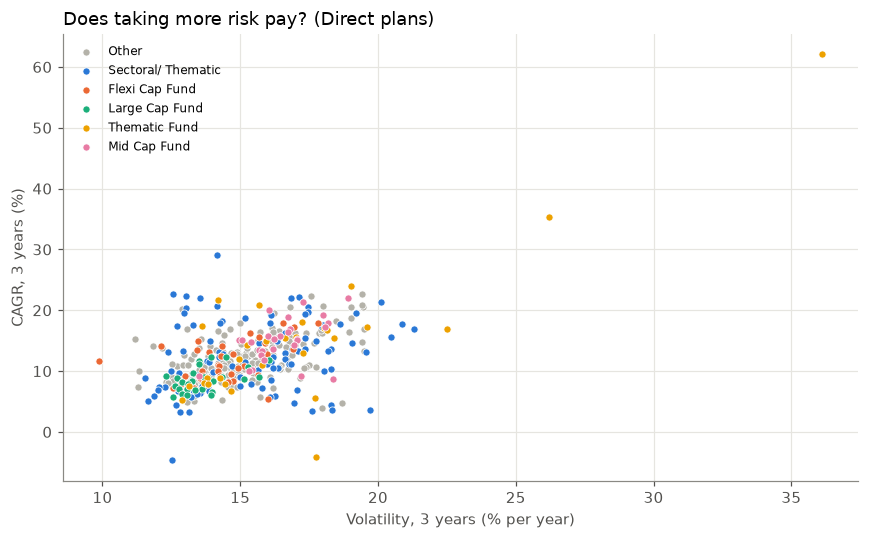

Correlation between 3y volatility and 3y CAGR: 0.58


,funds,median_cagr_3y,median_vol_3y,median_sharpe,worst_drawdown
sub_category,,,,,
Mid Cap Fund,28,0.152,0.163,0.541,-0.260
Sectoral Fund,9,0.157,0.162,0.539,-0.288
Small Cap Fund,24,0.144,0.169,0.490,-0.309
Thematic Fund,29,0.149,0.159,0.487,-0.376
Multi Cap Fund,22,0.129,0.151,0.430,-0.253
Contra Fund,3,0.125,0.147,0.397,-0.189
Large & Mid Cap Fund,26,0.119,0.152,0.347,-0.261
Sectoral/ Thematic,100,0.116,0.155,0.337,-0.419
Flexi Cap Fund,36,0.108,0.143,0.295,-0.267


In [5]:
d = metrics[(metrics.plan_type == "Direct")].dropna(subset=["cagr_3y", "volatility_3y"])
top_cats = d.sub_category.value_counts().head(5).index.tolist()
fig, ax = plt.subplots(figsize=(8, 5))
other = d[~d.sub_category.isin(top_cats)]
if len(other):
    ax.scatter(other.volatility_3y * 100, other.cagr_3y * 100, s=22, color=GREY, label="Other", edgecolor="white", linewidth=0.5)
for cat, col in zip(top_cats, CAT_COLORS):
    s = d[d.sub_category == cat]
    ax.scatter(s.volatility_3y * 100, s.cagr_3y * 100, s=22, color=col, label=cat, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Volatility, 3 years (% per year)"); ax.set_ylabel("CAGR, 3 years (%)")
ax.set_title("Does taking more risk pay? (Direct plans)", loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=8, loc="best")
plt.tight_layout(); plt.savefig(IMG_DIR / "risk_vs_return.png", bbox_inches="tight"); plt.show()

corr = d[["volatility_3y", "cagr_3y", "sharpe_3y"]].corr().loc["volatility_3y", "cagr_3y"]
print(f"Correlation between 3y volatility and 3y CAGR: {corr:.2f}")
cat_table = (d.groupby("sub_category")
               .agg(funds=("scheme_code", "size"),
                    median_cagr_3y=("cagr_3y", "median"),
                    median_vol_3y=("volatility_3y", "median"),
                    median_sharpe=("sharpe_3y", "median"),
                    worst_drawdown=("max_drawdown_3y", "min"))
               .sort_values("median_sharpe", ascending=False))
display(cat_table.round(3))

Based on 1569 fund-year moves


,Q1 next year,Q2 next year,Q3 next year,Q4 next year
Q1 this year,29.8,25.1,19.0,26.1
Q2 this year,25.1,25.4,27.6,21.9
Q3 this year,17.4,26.8,30.4,25.5
Q4 this year,26.3,18.8,22.4,32.5



Only 30% of top-quartile funds stay top-quartile the next year (25% = pure chance)


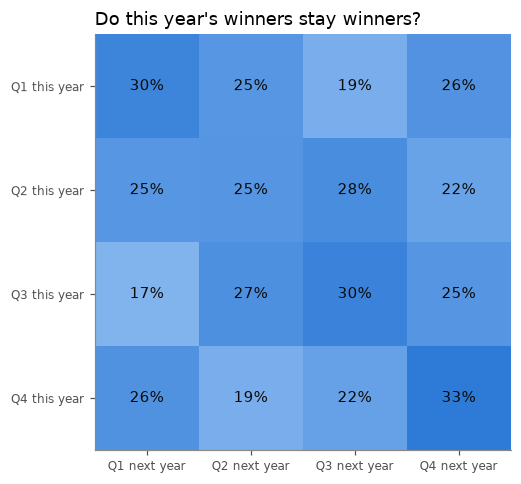

In [6]:
dec = rolling[(pd.to_datetime(rolling.month).dt.month == 12) & (rolling.plan_type == "Direct")].dropna(subset=["rolling_1y_return"]).copy()
dec["year"] = pd.to_datetime(dec.month).dt.year
dec["quartile"] = (dec.groupby(["year", "sub_category"]).rolling_1y_return
                     .transform(lambda s: pd.qcut(s.rank(method="first"), 4, labels=[1, 2, 3, 4]) if len(s) >= 8 else np.nan))
dec = dec.dropna(subset=["quartile"])
dec["quartile"] = 5 - dec.quartile.astype(int)        # 1 = best 25%
nxt = dec[["scheme_code", "year", "quartile"]].copy()
nxt["year"] -= 1
moves = dec.merge(nxt, on=["scheme_code", "year"], suffixes=("_this", "_next"))
matrix = pd.crosstab(moves.quartile_this, moves.quartile_next, normalize="index") * 100
matrix.index = [f"Q{i} this year" for i in matrix.index]
matrix.columns = [f"Q{i} next year" for i in matrix.columns]
print(f"Based on {len(moves)} fund-year moves")
display(matrix.round(1))
stay_top = matrix.iloc[0, 0]
print(f"\nOnly {stay_top:.0f}% of top-quartile funds stay top-quartile the next year (25% = pure chance)")

ramp = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"])
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(matrix.values, cmap=ramp, vmin=0, vmax=max(50, matrix.values.max()))
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        v = matrix.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 35 else "#0b0b0b", fontsize=10)
ax.set_xticks(range(4), matrix.columns, fontsize=8); ax.set_yticks(range(4), matrix.index, fontsize=8)
ax.grid(False)
ax.set_title("Do this year's winners stay winners?", loc="left", fontsize=12)
plt.tight_layout(); plt.savefig(IMG_DIR / "winner_persistence.png", bbox_inches="tight"); plt.show()